# Лабораторная работа №3

## Равномерное распределение

Для того, чтобы быстро искать моменты $k$-го порядка, можно вывести формулу.

$$\mathbb{E}[X^k]= \int_{-\infty}^{\infty}x^{k} \frac{1}{b-a} dx = \int_{a}^{b}x^{k} \frac{1}{b-a} dx = \frac{1}{b-a} \left. \frac{x^{k+1}}{k+1} \right |_{a}^{b} = \frac{b^{k+1} - a^{k+1}}{(k+1) (b-a)}$$
Необходимо решить систему из двух уравнений:

$$
\begin{cases}
\frac{\hat{a}+\hat{b}}{2} = \overline{X} \\
\frac{\hat{a}^2 + \hat{b}^2 + \hat{a}\hat{b}}{3} = \overline{X^2}
\end{cases}
$$

$$
\hat{a}^2 + \hat{a} \cdot (2\overline{X} - \hat{a}) + 4\overline{X}^2 - 4\overline{X}\hat{a} + \hat{a}^2 = 3\overline{X^2}
$$

$$
\hat{a}^2 - 2\hat{a}\overline{X} + 4\overline{X}^2 - 3\overline{X^2} = 0
$$

$$
D = 4\overline{X}^2 - 16\overline{X}^2 + 12\overline{X^2} = 12(\overline{X^2} - \overline{X}^2)
$$

$$
\hat{a} = \frac{2\overline{X} - 2\sqrt{3(\overline{X^2} - \overline{X}^2)}}{2} = \overline{X} - \sqrt{3(\overline{X^2} - \overline{X}^2)}
$$

$$
\hat{b} = \overline{X} + \sqrt{3(\overline{X^2} - \overline{X}^2)}
$$

In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")
n_arr = np.arange(10, 10000, 10)
a_arr = []
b_arr = []
for n in n_arr:
    data = np.random.uniform(size=n)
    mean_data = data.mean()
    mean_sq_data = (data**2).mean()
    a = mean_data - np.sqrt(3 * (mean_sq_data - mean_data ** 2))
    b = mean_data + np.sqrt(3 * (mean_sq_data - mean_data ** 2))
    a_arr.append(a)
    b_arr.append(b)

Text(0.5, 1.0, 'Зависимость оценки параметра a от величины выборки')

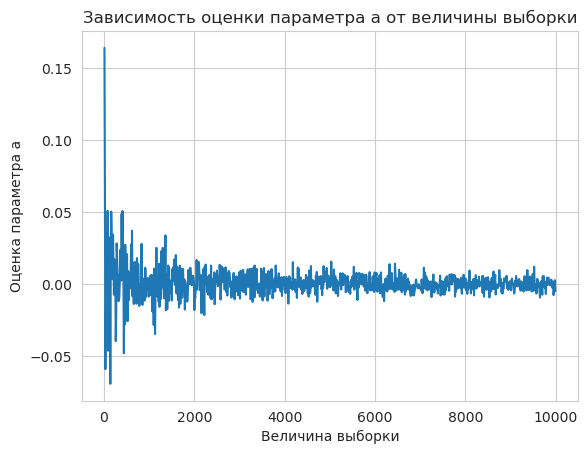

In [2]:
ax = sns.lineplot(x=n_arr, y=a_arr)
ax.set_xlabel('Величина выборки')
ax.set_ylabel('Оценка параметра a')
ax.set_title('Зависимость оценки параметра a от величины выборки')

Text(0.5, 1.0, 'Зависимость оценки параметра b от величины выборки')

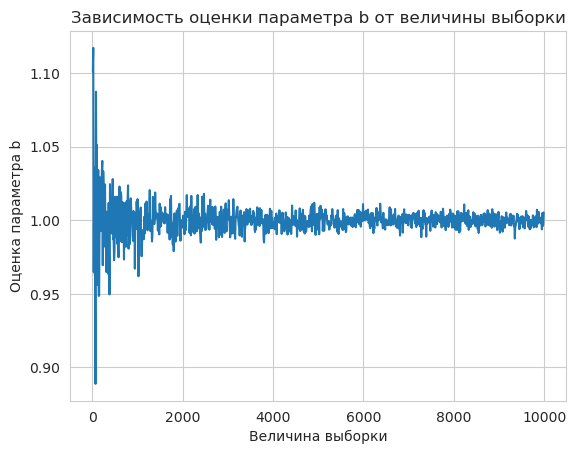

In [3]:
ax = sns.lineplot(x=n_arr, y=b_arr)
ax.set_xlabel('Величина выборки')
ax.set_ylabel('Оценка параметра b')
ax.set_title('Зависимость оценки параметра b от величины выборки')

In [4]:
def get_W(data, max_moment):
    moments = np.array([data**(i+1) / len(data) for i in range(max_moment)])
    return np.linalg.inv(np.cov(moments))

In [5]:
def gmm_uniform(params, data, max_moment, W):
    a, b = params
    loss = np.zeros(shape=(max_moment,))
    for i in range(max_moment):
        moment = (data**(i+1)).mean()
        loss[i] = moment - ((b**(i+2) - a**(i+2)) / ((i+2) * (b-a)))
    return loss @ W @ loss

In [6]:
from scipy.optimize import minimize


def plot_gmm(type_W='E'):
    n_moments = [3, 5, 7]
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    W = None
    a_arr = {3: [], 5: [], 7: []}
    b_arr = {3: [], 5: [], 7: []}
    for n in n_arr:
        data = np.random.uniform(size=n)
        for max_moment in n_moments:
            if type_W == 'E':
                W = np.eye(max_moment, max_moment)
            elif type_W == 'cov^{-1}':
                W = get_W(data, max_moment)
            result = minimize(
                fun=gmm_uniform,
                x0=(-1, 1),
                args=(data, max_moment, W),
                method='L-BFGS-B'
            )
            a, b = result.x
            a_arr[max_moment].append(a)
            b_arr[max_moment].append(b)
    for max_moment in n_moments:
        sns.lineplot(x=n_arr, y=a_arr[max_moment], ax=axes[0], label=f'W={type_W}, {max_moment} moments')
        sns.lineplot(x=n_arr, y=b_arr[max_moment], ax=axes[1], label=f'W={type_W}, {max_moment} moments')
        
    axes[0].set_xlabel('Величина выборки')
    axes[0].set_ylabel('Оценка параметра a')
    axes[0].set_title('Зависимость оценки параметра а от величины выборки')
    axes[0].set_ylim(-0.25, 0.25)
    
    axes[1].set_xlabel('Величина выборки')
    axes[1].set_ylabel('Оценка параметра b')
    axes[1].set_title('Зависимость оценки параметра b от величины выборки')
    axes[1].set_ylim(0.75, 1.25)
    
    plt.tight_layout()
    plt.show()

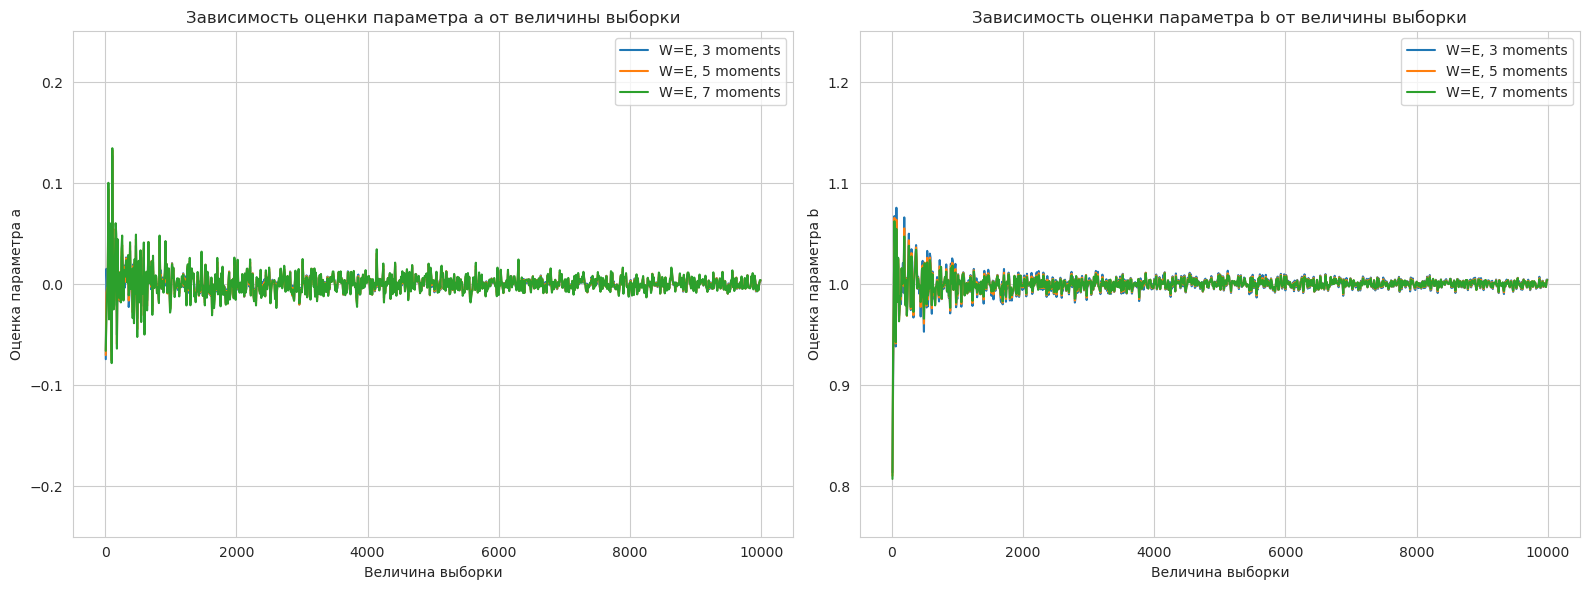

In [7]:
plot_gmm('E')

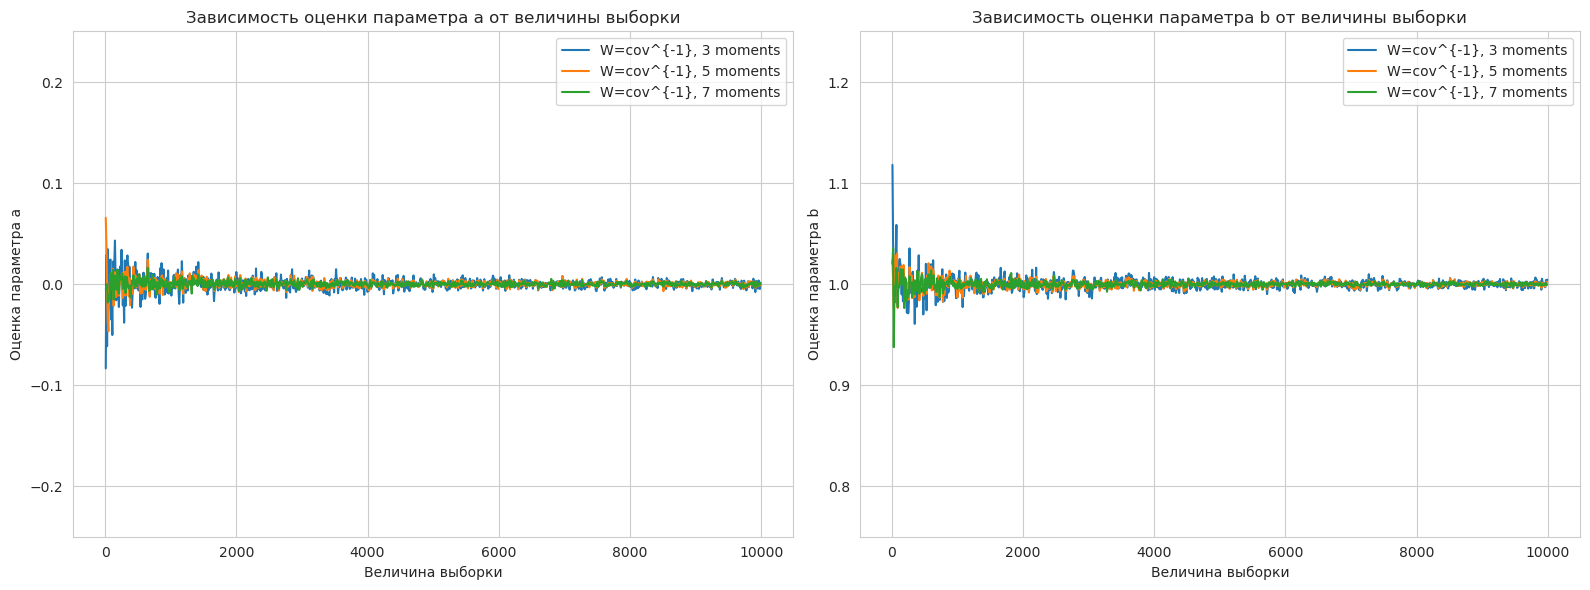

In [8]:
plot_gmm('cov^{-1}')

In [9]:
n_arr = np.arange(50, 1000, 50)
n_repeats = 1000
std_data = {
    "a_mm": [],
    "b_mm": [],
    "a_gmm": {3: [], 5: [], 7: []},
    "b_gmm": {3: [], 5: [], 7: []}
}

mean_data = {
    "a_mm": [],
    "b_mm": [],
    "a_gmm": {3: [], 5: [], 7: []},
    "b_gmm": {3: [], 5: [], 7: []}
}

for n in n_arr:
    a_mm = []
    b_mm = []
    a_gmm = {3: [], 5: [], 7: []}
    b_gmm = {3: [], 5: [], 7: []}
    for _ in range(n_repeats):
        data = np.random.uniform(size=n)
        mean_sample = data.mean()
        mean_sq_sample = (data**2).mean()
        a = mean_sample - np.sqrt(3 * (mean_sq_sample - mean_sample ** 2))
        b = mean_sample + np.sqrt(3 * (mean_sq_sample - mean_sample ** 2))
        a_mm.append(a)
        b_mm.append(b)
        for max_moment in [3, 5, 7]:
            result = minimize(fun=gmm_uniform, x0=(-1, 1), args=(data, max_moment, get_W(data, max_moment)), method='L-BFGS-B')
            a, b = result.x
            a_gmm[max_moment].append(a)
            b_gmm[max_moment].append(b)
    std_data["a_mm"].append(np.std(a_mm))
    std_data["b_mm"].append(np.std(b_mm))
    mean_data["a_mm"].append(np.mean(a_mm))
    mean_data["b_mm"].append(np.mean(b_mm))
    for max_moment in [3, 5, 7]:
        std_data["a_gmm"][max_moment].append(np.std(a_gmm[max_moment]))
        std_data["b_gmm"][max_moment].append(np.std(b_gmm[max_moment]))
        mean_data["a_gmm"][max_moment].append(np.mean(a_gmm[max_moment]))
        mean_data["b_gmm"][max_moment].append(np.mean(b_gmm[max_moment]))

Text(0.5, 1.0, 'Зависимость std оценки параметра b \nот величины выборки')

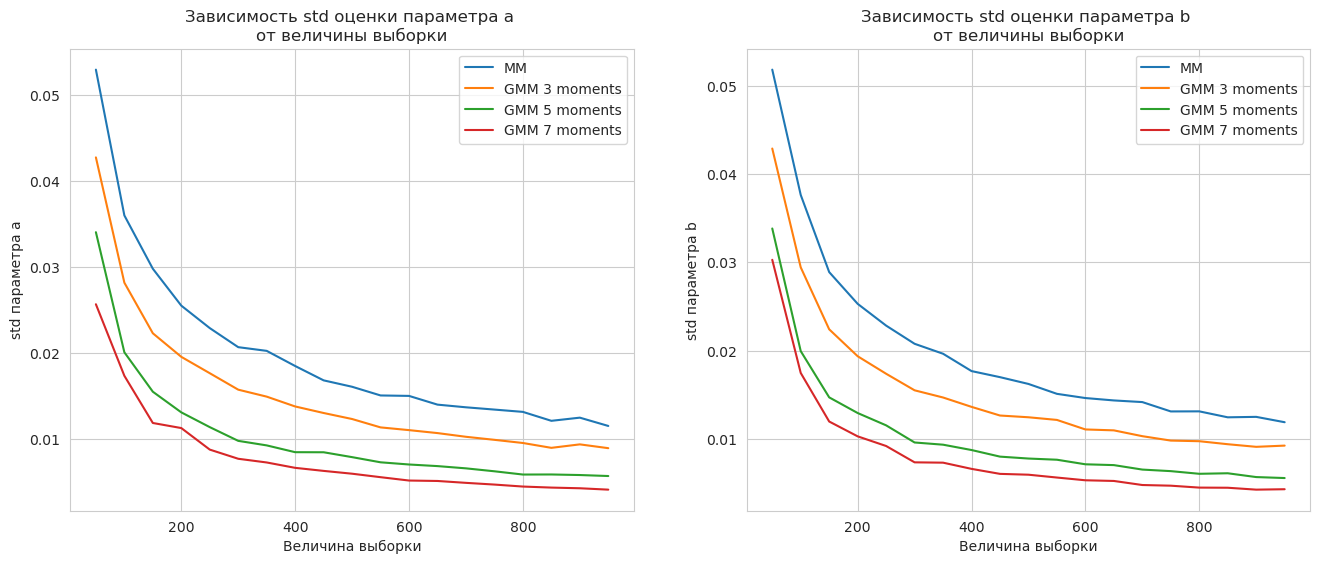

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.lineplot(x=n_arr, y=std_data["a_mm"], label='ММ', ax=axes[0])
for max_moment in [3, 5, 7]:
    sns.lineplot(x=n_arr, y=std_data["a_gmm"][max_moment], label=f'GMM {max_moment} moments', ax=axes[0])
axes[0].set_xlabel('Величина выборки')
axes[0].set_ylabel('std параметра a')
axes[0].set_title('Зависимость std оценки параметра a \nот величины выборки')

sns.lineplot(x=n_arr, y=std_data["b_mm"], label='ММ', ax=axes[1])
for max_moment in [3, 5, 7]:
    sns.lineplot(x=n_arr, y=std_data["b_gmm"][max_moment], label=f'GMM {max_moment} moments', ax=axes[1])
axes[1].set_xlabel('Величина выборки')
axes[1].set_ylabel('std параметра b')
axes[1].set_title('Зависимость std оценки параметра b \nот величины выборки')

Text(0.5, 1.0, 'Зависимость среднего значения оценки параметра b \nот величины выборки')

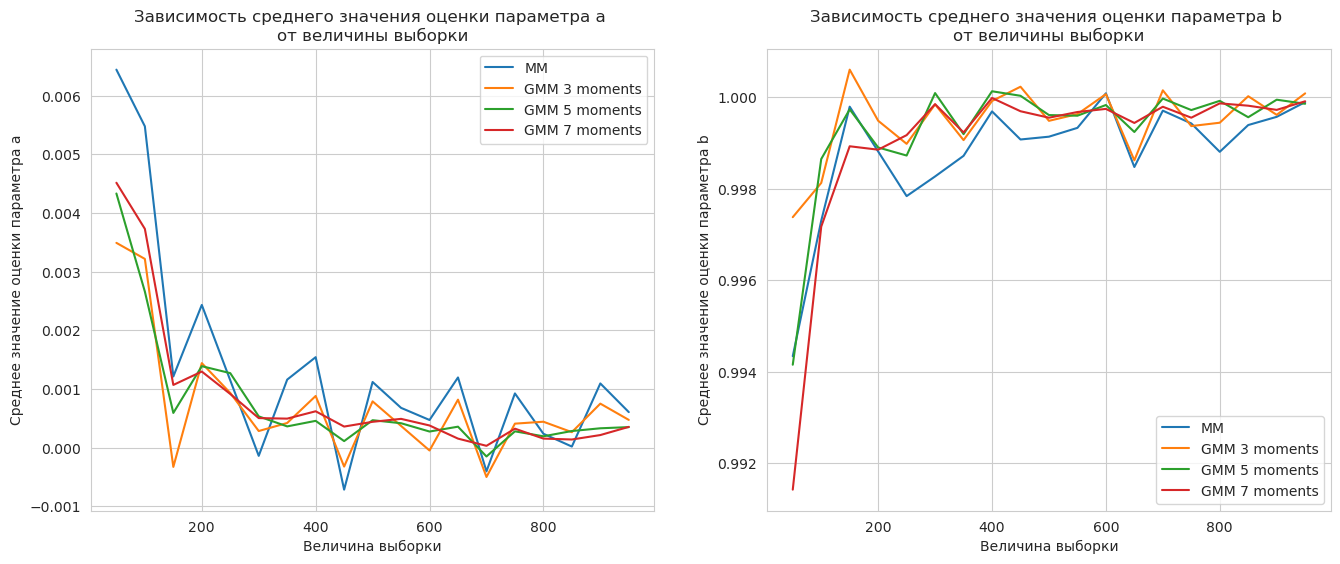

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.lineplot(x=n_arr, y=mean_data["a_mm"], label='ММ', ax=axes[0])
for max_moment in [3, 5, 7]:
    sns.lineplot(x=n_arr, y=mean_data["a_gmm"][max_moment], label=f'GMM {max_moment} moments', ax=axes[0])
axes[0].set_xlabel('Величина выборки')
axes[0].set_ylabel('Среднее значение оценки параметра a')
axes[0].set_title('Зависимость среднего значения оценки параметра a \nот величины выборки')

sns.lineplot(x=n_arr, y=mean_data["b_mm"], label='ММ', ax=axes[1])
for max_moment in [3, 5, 7]:
    sns.lineplot(x=n_arr, y=mean_data["b_gmm"][max_moment], label=f'GMM {max_moment} moments', ax=axes[1])
axes[1].set_xlabel('Величина выборки')
axes[1].set_ylabel('Среднее значение оценки параметра b')
axes[1].set_title('Зависимость среднего значения оценки параметра b \nот величины выборки')

## Экспоненциальное распределение

Для того, чтобы быстро искать моменты $k$-го порядка, можно вывести формулу.

$$\mathbb{E}[X^{k}] = \int_{-\infty}^{+\infty}x^k \lambda e^{-\lambda x} dx= \int_{0}^{+\infty}x^k \lambda e^{-\lambda x} dx$$

Пусть $U=x^k$, $dV=e^{-\lambda x} dx$

$dU = k x^{k-1}$, $V = \frac{e^{-\lambda x}}{- \lambda}$

$$\mathbb{E}[X^{k}] =  \lambda [\left. \frac{x^k}{-\lambda e^{\lambda x}} \right|_0^{\infty} + \frac{k}{\lambda} \int_{0}^{+\infty} x^{k-1} e^{-\lambda x}]$$

$$\lim_{x \rightarrow +\infty} \frac{x^k}{e^{\lambda x}} = \lim_{x \rightarrow +\infty} \frac{k x^{k-1}}{\lambda e^{\lambda x}} = ... = \lim_{x \rightarrow +\infty} \frac{k!}{\lambda^{k} e^{\lambda x}} = 0$$.

Многократно применяя правило Лопиталя, можно придти к тому, что предел выше стремится к 0.

$$\mathbb{E}[X^{k}] =  k \int_{0}^{+\infty} x^{k-1} e^{-\lambda x}$$

$$\mathbb{E}[X^{k-1}] = \lambda \int_{0}^{+\infty}x^{k-1} e^{-\lambda x} dx$$

$$\mathbb{E}[X^{k}] = \frac{k}{\lambda} \mathbb{E}[X^{k-1}] = \frac{k (k-1)}{\lambda ^ 2} \mathbb{E}[X^{k-2}] = ... = \frac{k!}{\lambda^{k}}$$

Таким образом, $$\overline{X} = \frac{1}{\hat{\lambda}}$$

$$\hat{\lambda}=\frac{1}{\overline{X}}$$

In [12]:
n_arr = np.arange(10, 10000, 10)
lam_arr = []
for n in n_arr:
    data = np.random.exponential(scale=4, size=n)
    mean_data = data.mean()
    lam_arr.append(1 / mean_data)

Text(0.5, 1.0, 'Зависимость оценки параметра интенсивности от величины выборки')

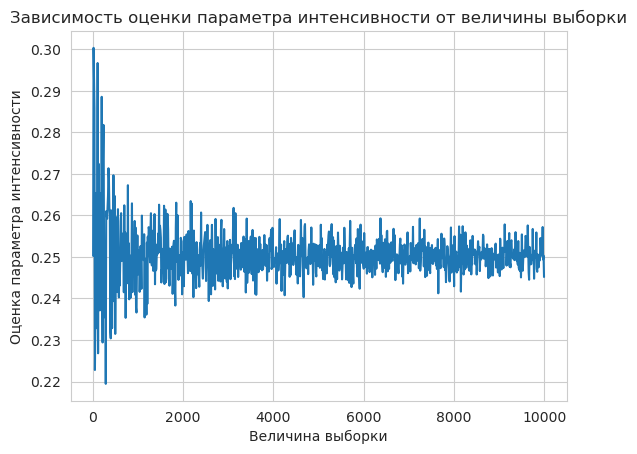

In [13]:
ax = sns.lineplot(x=n_arr, y=lam_arr)
ax.set_xlabel('Величина выборки')
ax.set_ylabel('Оценка параметра интенсивности')
ax.set_title('Зависимость оценки параметра интенсивности от величины выборки')

In [14]:
from scipy.special import factorial

def gmm_exp(params, data, max_moment, W):
    lam = params[0]
    loss = np.zeros(shape=(max_moment,))
    for i in range(max_moment):
        moment = (data**(i+1)).mean()
        loss[i] = moment - factorial(i + 1) / (lam ** (i+1))
    return loss @ W @ loss

In [15]:
def plot_gmm_exp(type_W=None):
    n_moments = [3, 5, 7]
    W = None
    lam_arr = {3: [], 5: [], 7: []}
    for n in n_arr:
        data = np.random.exponential(scale=4, size=n)
        for max_moment in n_moments:
            if type_W == 'E':
                W = np.eye(max_moment, max_moment)
            elif type_W == 'cov^{-1}':
                W = get_W(data, max_moment)
            result = minimize(
                fun=gmm_exp,
                x0=(1,),
                args=(data, max_moment, W),
                method='L-BFGS-B',bounds=[(1e-06, None)]
            )
            lam = result.x[0]
            lam_arr[max_moment].append(lam)
    for max_moment in n_moments:
        ax = sns.lineplot(x=n_arr, y=lam_arr[max_moment], label=f'W={type_W}, {max_moment} moments')
    ax.set_ylim(0, 1)
    ax.set_xlabel('Величина выборки')
    ax.set_ylabel('Оценка параметра интенсивности')
    ax.set_title('Зависимость оценки параметра интенсивности от величины выборки')

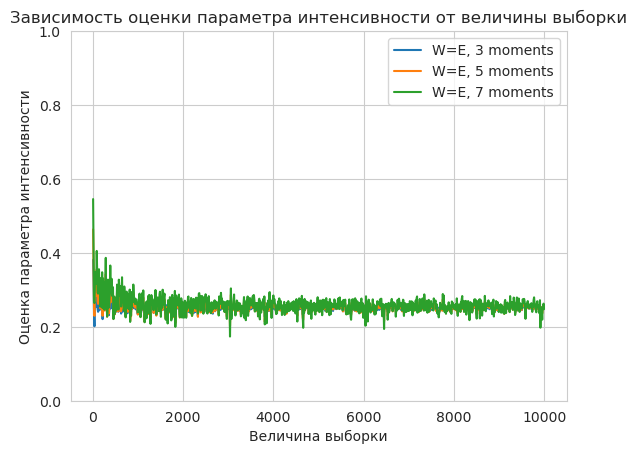

In [16]:
plot_gmm_exp('E')

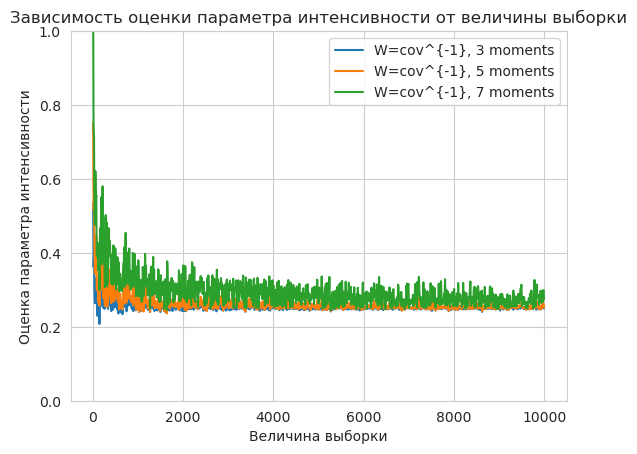

In [17]:
plot_gmm_exp('cov^{-1}')

In [18]:
def collect_metrics_exp(type_W='E'):
    n_arr = np.arange(50, 1000, 50)
    n_repeats = 1000
    
    std_data = {
        "lam_mm": [],
        "lam_gmm": {3: [], 5: [], 7: []},
    }
    
    mean_data = {
        "lam_mm": [],
        "lam_gmm": {3: [], 5: [], 7: []},
    }
    
    for n in n_arr:
        lam_mm = []
        lam_gmm = {3: [], 5: [], 7: []}
        for _ in range(n_repeats):
            data = np.random.exponential(scale=4, size=n)
            sample_mean = data.mean()
            lam_mm.append(1 / sample_mean)
            for max_moment in [3, 5, 7]:
                if type_W == 'E':
                    W = np.eye(max_moment)
                elif type_W == 'cov^{-1}':
                    W = get_W(data, max_moment)
                result = minimize(
                    fun=gmm_exp,
                    x0=(1,),
                    args=(data, max_moment, W),
                    method='L-BFGS-B',
                    bounds=[(1e-6, None)]
                )
                lam = result.x[0]
                lam_gmm[max_moment].append(lam)
        std_data["lam_mm"].append(np.std(lam_mm))
        mean_data["lam_mm"].append(np.mean(lam_mm))
        for max_moment in [3, 5, 7]:
            std_data["lam_gmm"][max_moment].append(np.std(lam_gmm[max_moment]))
            mean_data["lam_gmm"][max_moment].append(np.mean(lam_gmm[max_moment]))
    return std_data, mean_data

Text(0.5, 1.0, 'Зависимость std оценки параметра интенсивности \nот величины выборки')

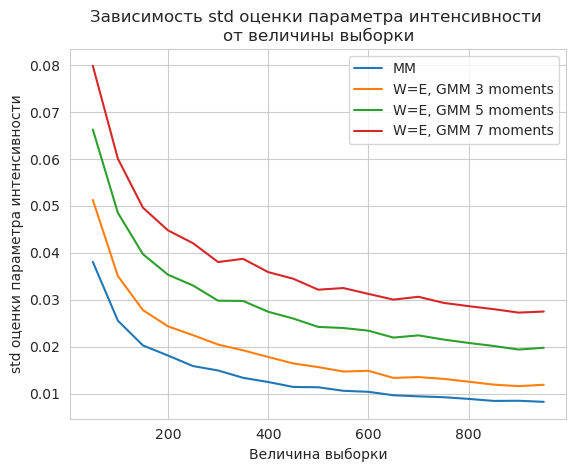

In [19]:
n_arr = np.arange(50, 1000, 50)
std_data, mean_data = collect_metrics_exp('E')
sns.lineplot(x=n_arr, y=std_data["lam_mm"], label='ММ')
for max_moment in [3, 5, 7]:
    ax = sns.lineplot(x=n_arr, y=std_data["lam_gmm"][max_moment], label=f'W=E, GMM {max_moment} moments')
ax.set_xlabel('Величина выборки')
ax.set_ylabel('std оценки параметра интенсивности')
ax.set_title('Зависимость std оценки параметра интенсивности \nот величины выборки')

Text(0.5, 1.0, 'Зависимость среднего значения оценки параметра интенсивности \nот величины выборки')

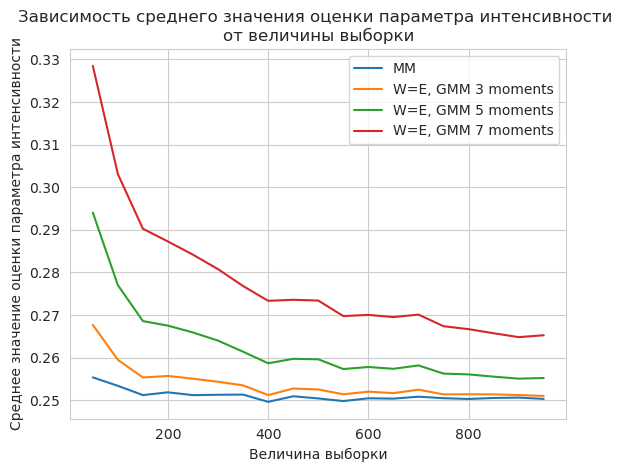

In [20]:
sns.lineplot(x=n_arr, y=mean_data["lam_mm"], label='ММ')
for max_moment in [3, 5, 7]:
    ax = sns.lineplot(x=n_arr, y=mean_data["lam_gmm"][max_moment], label=f'W=E, GMM {max_moment} moments')
ax.set_xlabel('Величина выборки')
ax.set_ylabel('Среднее значение оценки параметра интенсивности')
ax.set_title('Зависимость среднего значения оценки параметра интенсивности \nот величины выборки')

Text(0.5, 1.0, 'Зависимость std оценки параметра интенсивности \nот величины выборки')

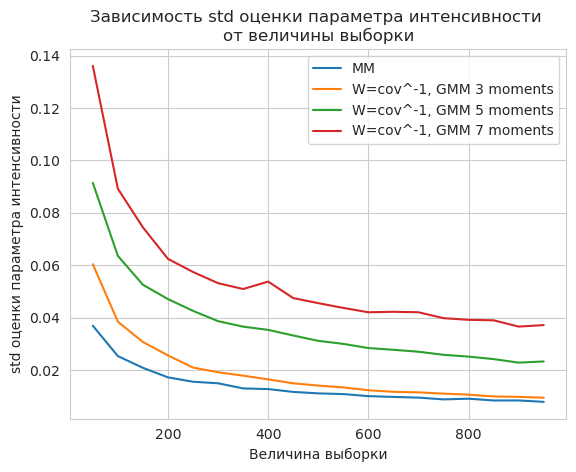

In [21]:
std_data, mean_data = collect_metrics_exp('cov^{-1}')
sns.lineplot(x=n_arr, y=std_data["lam_mm"], label='ММ')
for max_moment in [3, 5, 7]:
    ax = sns.lineplot(x=n_arr, y=std_data["lam_gmm"][max_moment], label=f'W=cov^{-1}, GMM {max_moment} moments')
ax.set_xlabel('Величина выборки')
ax.set_ylabel('std оценки параметра интенсивности')
ax.set_title('Зависимость std оценки параметра интенсивности \nот величины выборки')

Text(0.5, 1.0, 'Зависимость среднего значения оценки параметра интенсивности \nот величины выборки')

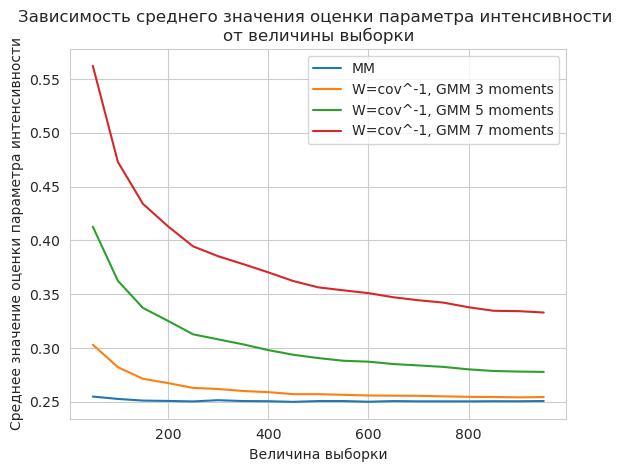

In [22]:
sns.lineplot(x=n_arr, y=mean_data["lam_mm"], label='ММ')
for max_moment in [3, 5, 7]:
    ax = sns.lineplot(x=n_arr, y=mean_data["lam_gmm"][max_moment], label=f'W=cov^{-1}, GMM {max_moment} moments')
ax.set_xlabel('Величина выборки')
ax.set_ylabel('Среднее значение оценки параметра интенсивности')
ax.set_title('Зависимость среднего значения оценки параметра интенсивности \nот величины выборки')


# Выводы

## Равномерное распределение

1. С помощью метода моментов были получены оценки параметров равномерного распределения и построены графики их зависимости от объёма выборки. Анализ полученных графиков показал, что с увеличением объёма выборки оценки параметров приближаются к их теоретическим значениям.

2. С помощью обобщённого метода моментов были получены оценки параметров равномерного распределения и построены графики их зависимости от объёма выборки. На основании полученных результатов можно сделать вывод, что использование обратной ковариационной матрицы в качестве весовой вместо единичной позволяет добиться более быстрого приближения оценок параметров к их теоретическим значениям в рассмотренных экспериментах.

3. Были построены графики зависимости среднего значения оценок параметров равномерного распределения и их среднеквадратического отклонения от объёма выборки. Анализ графиков показал, что при фиксированном объёме выборки увеличение количества используемых моментных условий приводит к уменьшению среднеквадратического отклонения оценок параметров.

## Экспоненциальное распределение

1. С помощью метода моментов была получена оценка параметра интенсивности экспоненциального распределения и построен график её зависимости от объёма выборки. Анализ полученных результатов показал, что с увеличением объёма выборки оценка параметра приближается к его теоретическому значению.

2. С помощью обобщённого метода моментов была получена оценка параметра интенсивности экспоненциального распределения и построены графики её зависимости от объёма выборки. Анализ графиков показал, что при использовании обратной ковариационной матрицы в качестве весовой вместо единичной наблюдаются более выраженные колебания оценок относительно теоретического значения параметра. Особенно заметно это проявляется при использовании семи моментных условий. Предположительно, такой результат связан с тем, что для оценивания параметра интенсивности экспоненциального распределения достаточно первого моментного условия. Кроме того, моменты различных порядков сильно коррелируют между собой, что может приводить к неустойчивости оценки ковариационной матрицы и её обращения при ограниченном объёме выборки.

3. Были построены графики зависимости среднего значения оценки параметра интенсивности экспоненциального распределения и её среднеквадратического отклонения от объёма выборки. Анализ полученных графиков показал, что при фиксированном объёме выборки увеличение количества используемых моментных условий сопровождается ростом среднеквадратического отклонения оценки. При этом использование обратной ковариационной матрицы в качестве весовой способствует уменьшению резких колебаний на графике зависимости среднеквадратического отклонения оценки от объёма выборки, благодаря чему кривая становится более гладкой.